# ch02_6. 주택가격 예측

- 실제 데이터로 다중 선형회귀의 일반화 성능 확인하기
- `housing.csv`에서 주택 데이터를 불러옵니다.
- 가중치와 잔차를 이용해 모델 결과를 해석합니다.

## 1. 라이브러리와 CSV 파일 준비

- CSV(씨에스브이, 쉼표로 구분된 데이터 파일)는 NumPy(넘파이)로 읽습니다.
- 이후 데이터 분리·표준화·학습은 PyTorch Tensor(파이토치 텐서)로 처리합니다.
- Colab(코랩)에서 파일이 없으면 업로드 창이 열립니다.

In [ ]:
#01_데이터 준비
from pathlib import Path

import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 노트북과 같은 폴더의 housing.csv를 읽습니다.
data_path = Path("housing.csv")


# Colab에서 파일이 없으면 업로드 창을 엽니다.
# if not data_path.exists():
#     try:
#         from google.colab import files
#         files.upload()
#     except ImportError:
#         pass

# if not data_path.exists():
#     raise FileNotFoundError("현재 폴더에 housing.csv를 넣은 뒤 다시 실행해 주세요.")


## 2. `housing.csv` 불러오기

첫 번째 줄은 열 이름이고, 나머지는 숫자 데이터입니다.

- 마지막 열: 목표값 `MEDV`
- 나머지 열: 주택가격 예측에 사용하는 입력 특성

In [ ]:
#02_첫 줄에서 열 이름 읽기
with data_path.open("r", encoding="utf-8") as file:
    column_names = file.readline().strip().split(",")

# 숫자 데이터 읽기
housing_array = np.loadtxt(
    data_path,
    delimiter=",",
    skiprows=1,
    dtype=np.float32,
)

feature_names = column_names[:-1]
target_name = column_names[-1]

print("데이터 수:", len(housing_array))
print("입력 특성 수:", len(feature_names))
print("목표값:", target_name)
print("앞부분 3행:")
print(housing_array[:3])

데이터 수: 506
입력 특성 수: 12
목표값: MEDV
앞부분 3행:
[[6.3200e-03 1.8000e+01 2.3100e+00 0.0000e+00 5.3800e-01 6.5750e+00
  6.5200e+01 4.0900e+00 1.0000e+00 2.9600e+02 1.5300e+01 4.9800e+00
  2.4000e+01]
 [2.7310e-02 0.0000e+00 7.0700e+00 0.0000e+00 4.6900e-01 6.4210e+00
  7.8900e+01 4.9671e+00 2.0000e+00 2.4200e+02 1.7800e+01 9.1400e+00
  2.1600e+01]
 [2.7290e-02 0.0000e+00 7.0700e+00 0.0000e+00 4.6900e-01 7.1850e+00
  6.1100e+01 4.9671e+00 2.0000e+00 2.4200e+02 1.7800e+01 4.0300e+00
  3.4700e+01]]


## 3. 입력 특성과 목표값 분리

입력 특성 12개:

- `CRIM`(크라임, 지역별 범죄율)
- `ZN`(지엔, 넓은 주거용 부지 비율)
- `INDUS`(인더스, 비소매 상업지역 비율)
- `CHAS`(채스, 찰스강 인접 여부)
- `NOX`(녹스, 질소산화물 농도)
- `RM`(알엠, 주택당 평균 방 수)
- `AGE`(에이지, 오래된 주택 비율)
- `DIS`(디아이에스, 고용 중심지까지의 거리)
- `RAD`(래드, 고속도로 접근성)
- `TAX`(택스, 재산세율)
- `PTRATIO`(피티레이쇼, 학생·교사 비율)
- `LSTAT`(엘스탯, 저소득 인구 비율)

목표값:

- `MEDV`(메드브이, 자가주택 가격 중앙값)
- 단위: 천 달러

In [ ]:
#03_NumPy 배열을 Tensor로 변환
housing_tensor = torch.tensor(housing_array,
                              dtype=torch.float32,)
x_all = housing_tensor[:, :-1]
y_all = housing_tensor[:, -1:]

print("전체 입력 shape:", x_all.shape)
print("전체 목표 shape:", y_all.shape)
print("첫 번째 입력:", x_all[0])
print("첫 번째 목표값:", y_all[0].item())

전체 입력 shape: torch.Size([506, 12])
전체 목표 shape: torch.Size([506, 1])
첫 번째 입력: tensor([6.3200e-03, 1.8000e+01, 2.3100e+00, 0.0000e+00, 5.3800e-01, 6.5750e+00,
        6.5200e+01, 4.0900e+00, 1.0000e+00, 2.9600e+02, 1.5300e+01, 4.9800e+00])
첫 번째 목표값: 24.0


## 4. 훈련 데이터와 테스트 데이터 분리

- 훈련 데이터 80%: 모델 학습
- 테스트 데이터 20%: 보지 않은 데이터의 예측 성능 확인

`torch.randperm()`으로 데이터 순서를 섞고, 같은 결과가 나오도록 난수 기준값을 고정합니다.

> 테스트 데이터는 모델 학습과 표준화 통계 계산에 사용하지 않습니다.

In [ ]:
#04_훈련데이터, 테스트데이터 분리 : 80% vs 20%

torch.manual_seed(42)

indices = torch.randperm(len(x_all))
train_count = int(len(x_all) * 0.8)

train_indices = indices[:train_count]
test_indices = indices[train_count:]

x_train = x_all[train_indices]
y_train = y_all[train_indices]

x_test = x_all[test_indices]
y_test = y_all[test_indices]

print("훈련 데이터:", x_train.shape, y_train.shape)
print("테스트 데이터:", x_test.shape, y_test.shape)

훈련 데이터: torch.Size([404, 12]) torch.Size([404, 1])
테스트 데이터: torch.Size([102, 12]) torch.Size([102, 1])


## 5. 입력 특성 표준화

특성마다 숫자의 범위가 크게 다릅니다.

- `CHAS`: 0 또는 1
- `TAX`: 수백 단위
- `CRIM`: 작은 소수부터 큰 값까지 분포

각 열을 평균 0, 표준편차 1에 가까운 값으로 바꿉니다.

$$
x_{\mathrm{scaled}}
=
\frac{x-\mu_{\mathrm{train}}}
{\sigma_{\mathrm{train}}}
$$

테스트 데이터에도 훈련 데이터에서 계산한 평균과 표준편차를 사용합니다.
테스트 통계량을 미리 사용하면 Data Leakage(데이터 리키지, 데이터 누출)가 발생합니다.

In [5]:
# 각 입력 특성의 평균과 표준편차
x_mean = x_train.mean(dim=0)
x_std = x_train.std(dim=0)

# 표준편차가 0인 특성이 있으면 1로 대체
x_std = torch.where(x_std == 0,torch.ones_like(x_std),x_std,)
x_train_scaled = (x_train - x_mean) / x_std
x_test_scaled = (x_test - x_mean) / x_std

print("표준화 후 평균:",torch.round(x_train_scaled.mean(dim=0),decimals=3,),)
print("표준화 후 표준편차:",torch.round(x_train_scaled.std(dim=0),decimals=3,),)

표준화 후 평균: tensor([-0., -0., -0., 0., 0., -0., 0., 0., 0., -0., 0., 0.])
표준화 후 표준편차: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 6. 주택가격 예측 모델

입력 특성 12개로 가격 1개를 예측하므로 다음 계층을 사용합니다.

```python
nn.Linear(12, 1)
```

$$
\hat{y}
=
w_1x_1+w_2x_2+\cdots+w_{12}x_{12}+b
$$

같은 선형 계층이므로 별도의 모델 클래스를 다시 만들지 않습니다.

In [ ]:
#06_주택가격 예측 모델

torch.manual_seed(42)

model = nn.Linear(len(feature_names),1,)

print(model)
print("가중치 shape:", model.weight.shape)
print("편향 shape:", model.bias.shape)

Linear(in_features=12, out_features=1, bias=True)
가중치 shape: torch.Size([1, 12])
편향 shape: torch.Size([1])


## 7. 모델 학습

학습 흐름은 와 같습니다.

$$
\text{순전파}
\rightarrow
\text{손실}
\rightarrow
\text{역전파}
\rightarrow
\text{갱신}
$$

목표값은 실제 천 달러 단위를 유지합니다.

In [ ]:
#07_모델 학습
loss_function = nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(),lr=0.03,)

epochs = 2000
loss_history = []

model.train()

for epoch in range(epochs):
    # 1. 순전파
    train_prediction = model(x_train_scaled)

    # 2. 손실 계산
    loss = loss_function(train_prediction, y_train)

    # 3. 이전 기울기 초기화
    optimizer.zero_grad()

    # 4. 역전파
    loss.backward()

    # 5. 가중치와 편향 갱신
    optimizer.step()

    loss_history.append(loss.item())

print("처음 Loss:", loss_history[0])
print("마지막 Loss:", loss_history[-1])

처음 Loss: 575.1853637695312
마지막 Loss: 20.720441818237305


## 8. 손실 변화 확인

학습이 진행되면서 MSE Loss(엠에스이 로스, 평균제곱오차 손실)가 감소하는지 확인합니다.

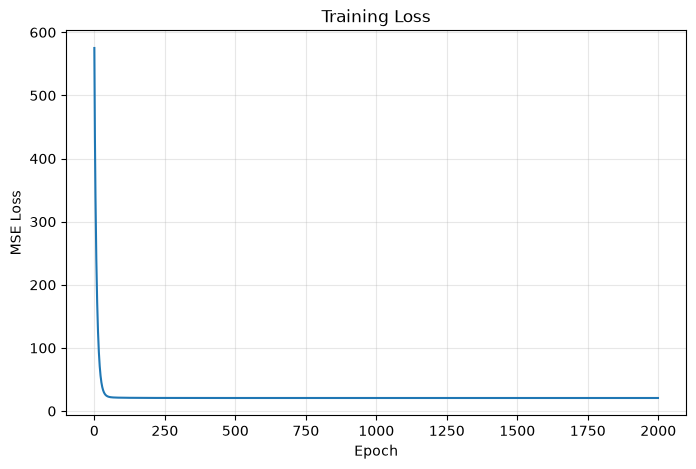

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)
plt.show()

## 9. 훈련·테스트 데이터 예측

- `model.eval()` : 평가 모드
- `torch.no_grad()` : 예측 중 기울기 계산 중지
- 훈련 예측: 학습 적합도 확인
- 테스트 예측: 일반화 성능 확인

In [ ]:
#09_훈련, 테스트 데이터 예측
model.eval()

with torch.no_grad():
    train_prediction = model(x_train_scaled)
    test_prediction = model(x_test_scaled)

print("테스트 실제값 5개:")
print(y_test[:5, 0])

print()
print("테스트 예측값 5개:")
print(torch.round(test_prediction[:5, 0], decimals=2,))

테스트 실제값 5개:
tensor([20.0000, 18.6000, 22.8000, 10.9000, 20.4000])

테스트 예측값 5개:
tensor([16.7300, 16.3000, 27.2200, 16.3400, 22.1100])


## 10. 회귀 성능 평가

사용한 세 지표를 그대로 적용합니다.

| 지표 | 의미 | 좋은 결과 |
|---|---|---|
| MAE | 평균적으로 몇 천 달러 틀리는지 표시 | 작을수록 좋음 |
| RMSE | 큰 오차에 더 민감한 평균 오차 | 작을수록 좋음 |
| $R^2$ | 주택가격 변화의 설명 정도 | 1에 가까울수록 좋음 |

훈련 결과와 테스트 결과를 함께 비교해야 합니다.

In [ ]:
#10_회귀 성능 평가

def regression_metrics(y_true, y_pred):
    error = y_pred - y_true

    mae = error.abs().mean()
    rmse = (error ** 2).mean().sqrt()

    residual_sum = (error ** 2).sum()
    total_sum = ((y_true - y_true.mean()) ** 2).sum()

    r2 = 1 - residual_sum / total_sum

    return mae, rmse, r2


train_mae, train_rmse, train_r2 = (
    regression_metrics(y_train, train_prediction,))

test_mae, test_rmse, test_r2 = ( 
    regression_metrics(y_test, test_prediction, ))

print("[훈련 데이터: 학습 적합도]")
print(f"MAE : {train_mae.item():.3f} 천 달러")
print(f"RMSE: {train_rmse.item():.3f} 천 달러")
print(f"R²  : {train_r2.item():.3f}")

print()
print("[테스트 데이터: 일반화 성능]")
print(f"MAE : {test_mae.item():.3f} 천 달러")
print(f"RMSE: {test_rmse.item():.3f} 천 달러")
print(f"R²  : {test_r2.item():.3f}")

[훈련 데이터: 학습 적합도]
MAE : 3.265 천 달러
RMSE: 4.552 천 달러
R²  : 0.747

[테스트 데이터: 일반화 성능]
MAE : 3.500 천 달러
RMSE: 5.629 천 달러
R²  : 0.663


## 11. 훈련 성능과 테스트 성능 해석

- 두 오차가 모두 큼 → Underfitting(언더피팅, 과소적합) 가능성
- 훈련 오차는 작고 테스트 오차가 크게 증가 → Overfitting(오버피팅, 과적합) 가능성
- 두 결과가 비슷함 → 학습한 관계가 새로운 데이터에도 비교적 유지

한 번의 데이터 분할 결과이므로 절대적인 성능 판정이 아니라 실습용 비교 기준으로 사용합니다.

In [ ]:
#11_훈련 성능과 테스트 성능 해석

rmse_gap = (test_rmse - train_rmse).item()

print("RMSE 차이(테스트 - 훈련):", round(rmse_gap, 3),)

if test_rmse > train_rmse * 1.3:
    print("해석: 테스트 오차 증가가 커서 과적합 가능성을 점검합니다.")
else:
    print("해석: 훈련과 테스트 오차 사이에 큰 급증은 없습니다.")

RMSE 차이(테스트 - 훈련): 1.077
해석: 훈련과 테스트 오차 사이에 큰 급증은 없습니다.


## 12. 실제값과 예측값 비교

점이 대각선에 가까울수록 예측이 정확합니다.

테스트 데이터만 사용하여 모델이 보지 않은 데이터의 결과를 확인합니다.

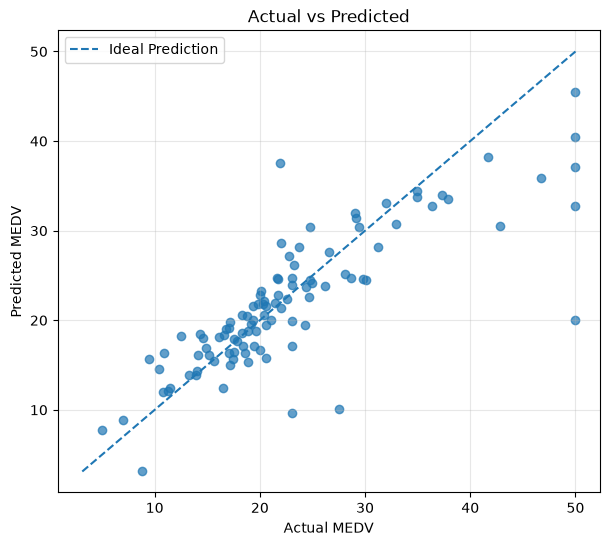

In [ ]:
#12_실제값과 예측값 비교

actual_values = y_test[:, 0].numpy()
predicted_values = (test_prediction[:, 0].numpy())

price_min = min(actual_values.min(), predicted_values.min(),)

price_max = max(actual_values.max(), predicted_values.max(),)

plt.figure(figsize=(7, 6))
plt.scatter(actual_values, predicted_values, alpha=0.7,)

plt.plot([price_min, price_max], [price_min, price_max],
    linestyle="--", label="Ideal Prediction",)

plt.xlabel("Actual MEDV")
plt.ylabel("Predicted MEDV")
plt.title("Actual vs Predicted")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 13. 잔차 확인

Residual(리주얼, 잔차)은 실제값에서 예측값을 뺀 값입니다.

$$
\text{Residual}
=
y-\hat{y}
$$

- 잔차가 0에 가까움 → 예측이 정확함
- 잔차가 양수 → 실제 가격보다 낮게 예측
- 잔차가 음수 → 실제 가격보다 높게 예측
- 특정 모양이 반복됨 → 직선 모델이 설명하지 못한 관계가 있을 수 있음

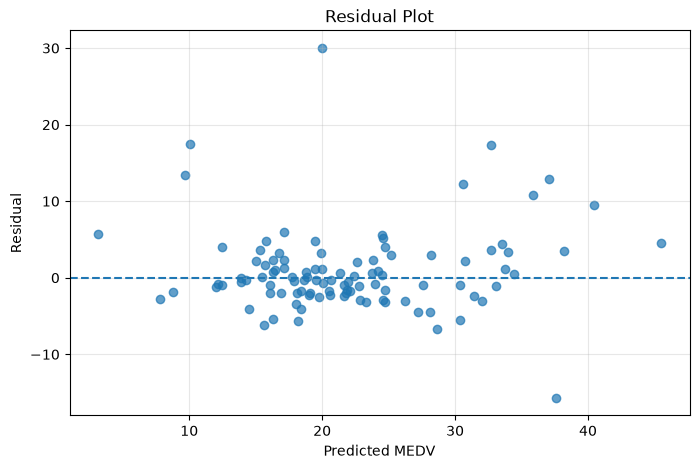

In [ ]:
#13_잔차: 실제값에서 예측값을 뺀 값
residuals = (actual_values - predicted_values)

plt.figure(figsize=(8, 5))
plt.scatter(predicted_values, residuals, alpha=0.7,)

plt.axhline(0, linestyle="--",)

plt.xlabel("Predicted MEDV")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid(alpha=0.3)
plt.show()

## 14. 표준화된 가중치 해석

입력 특성을 모두 표준화했으므로 가중치의 크기를 비교할 수 있습니다.

- 양수 가중치: 특성이 증가할수록 예측 가격이 증가하는 방향
- 음수 가중치: 특성이 증가할수록 예측 가격이 감소하는 방향
- 절댓값이 큰 가중치: 1 표준편차 변화에 대한 예측값 변화가 큼

가중치는 관계의 방향을 보여주지만, 인과관계를 증명하지는 않습니다.

In [ ]:
#14_표준화된 가중치 해석

weights = (model.weight.detach().squeeze(0))

weight_order = torch.argsort(weights.abs(), descending=True,)

print("절댓값이 큰 가중치부터 확인:")
for index in weight_order:
    feature_index = index.item()

    print(f"{feature_names[feature_index]:8s}: "
        f"{weights[feature_index].item(): .4f}")

절댓값이 큰 가중치부터 확인:
RM      :  3.0898
LSTAT   : -2.9926
DIS     : -2.9905
NOX     : -2.1885
PTRATIO : -2.1113
RAD     :  1.9562
TAX     : -1.9393
ZN      :  0.9172
CHAS    :  0.8213
CRIM    : -0.7282
AGE     : -0.2258
INDUS   : -0.0270


## 15. 주택 한 채의 예측 결과 확인

테스트 데이터의 첫 번째 주택에 대해:

- 입력 특성 12개
- 실제 가격
- 예측 가격
- 잔차

위 항목을 함께 확인합니다.

In [ ]:
#15_주택 한 채의 예측 결과 확인
sample_index = 0

sample_actual = (y_test[sample_index].item())
sample_prediction = (test_prediction[sample_index].item())
sample_residual = (sample_actual - sample_prediction)

print("입력 특성:")

for name, value in zip(feature_names, x_test[sample_index],):
    print(f"{name:8s}: {value.item():.4f}")

print()
print(f"실제 가격: {sample_actual:.2f} 천 달러")
print(f"예측 가격: {sample_prediction:.2f} 천 달러")
print(f"잔차    : {sample_residual:.2f} 천 달러")

입력 특성:
CRIM    : 6.8012
ZN      : 0.0000
INDUS   : 18.1000
CHAS    : 0.0000
NOX     : 0.7130
RM      : 6.0810
AGE     : 84.4000
DIS     : 2.7175
RAD     : 24.0000
TAX     : 666.0000
PTRATIO : 20.2000
LSTAT   : 14.7000

실제 가격: 20.00 천 달러
예측 가격: 16.73 천 달러
잔차      : 3.27 천 달러


## 17. 핵심 정리

- `housing.csv`에는 주택 데이터 506개가 들어 있습니다.
- 목표값을 실제 천 달러 단위로 유지하면 예측값 복원 과정이 필요 없습니다.
- 가중치는 관계의 방향을 보여주지만 인과관계를 증명하지는 않습니다.